# Data Visualization & Preprocessing

In [1]:
import os
import cv2
import matplotlib.pyplot as plt

In [2]:
dataset_path = "../../DR Dataset/train_images"

In [3]:
image_files = [f for f in os.listdir(dataset_path) if f.endswith('.png')][:5]

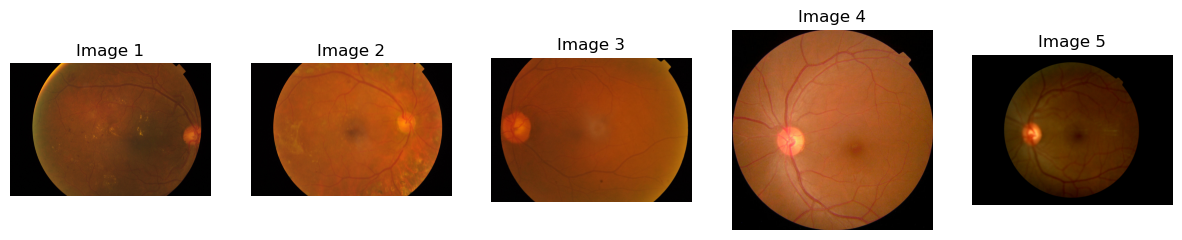

In [4]:
# Plot sample images
plt.figure(figsize=(15, 5))
for i, file in enumerate(image_files):
    img = cv2.imread(os.path.join(dataset_path, file))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert from BGR to RGB
    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.show()

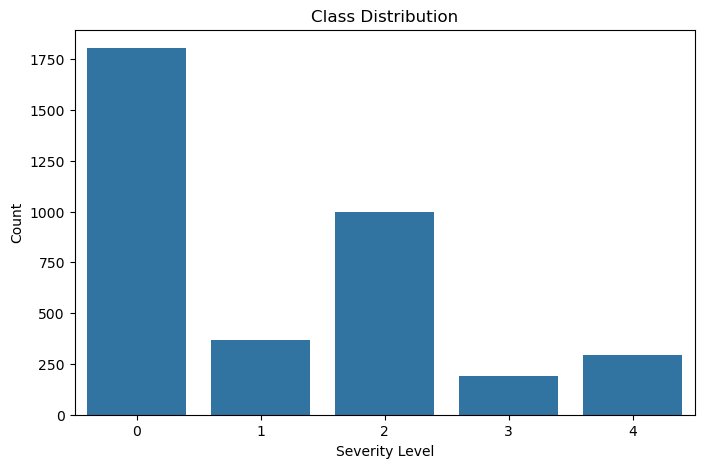

In [5]:
import pandas as pd
import seaborn as sns

# Load labels (Assuming CSV format)
labels_path = "../../DR Dataset/train.csv"  # Change as needed
df = pd.read_csv(labels_path)

# Check distribution
plt.figure(figsize=(8, 5))
sns.countplot(x=df["diagnosis"])  # 'diagnosis' column should contain severity (0-4)
plt.title("Class Distribution")
plt.xlabel("Severity Level")
plt.ylabel("Count")
plt.show()


In [6]:
# Convert to grayscale
def convert_to_grayscale(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    return img


In [37]:
def apply_clahe(image):
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)

    # Apply CLAHE to L-channel
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    l_clahe = clahe.apply(l)

    # Merge back and convert to RGB
    lab_clahe = cv2.merge((l_clahe, a, b))
    final_img = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)
    return final_img


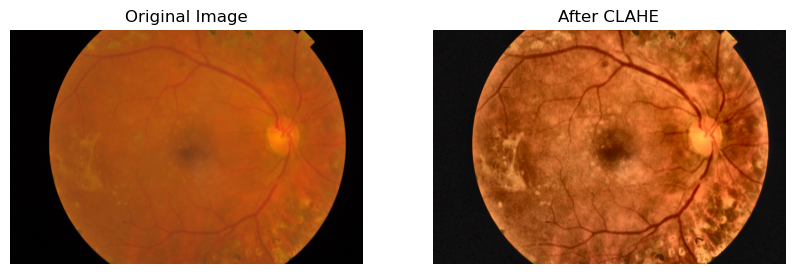

In [35]:
sample_img_path = os.path.join(dataset_path, image_files[1])
img = cv2.imread(sample_img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert from BGR to RGB
clahe_img = apply_clahe(img)

# Show before and after
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(clahe_img)
plt.title("After CLAHE")
plt.axis("off")

plt.show()


In [10]:
from albumentations import (
    HorizontalFlip, RandomBrightnessContrast, ShiftScaleRotate,
    GaussNoise, OpticalDistortion, GridDistortion, Compose
)
from albumentations.pytorch import ToTensorV2
import numpy as np

# Define augmentations
augmentation_pipeline = Compose([
    HorizontalFlip(p=0.5),
    RandomBrightnessContrast(p=0.3),
    ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=15, p=0.5),
    GaussNoise(var_limit=(10, 50), p=0.3),
    OpticalDistortion(distort_limit=0.05, p=0.3),
    GridDistortion(num_steps=5, distort_limit=0.05, p=0.3),
])


/home/abbask1552/miniconda3/envs/rapids-24.10/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/abbask1552/miniconda3/envs/rapids-24.10/lib/python3.10/site-packages/albumentations/__init__.py:28: UserWarning: A new version of Albumentations is available: '2.0.5' (you have '2.0.1'). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()
/home/abbask1552/miniconda3/envs/rapids-24.10/lib/python3.10/site-packages/albumentations/core/validation.py:45: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_660/4031642675.py:13: UserWarning: Argument 'var_limit' is not valid and will be ignore

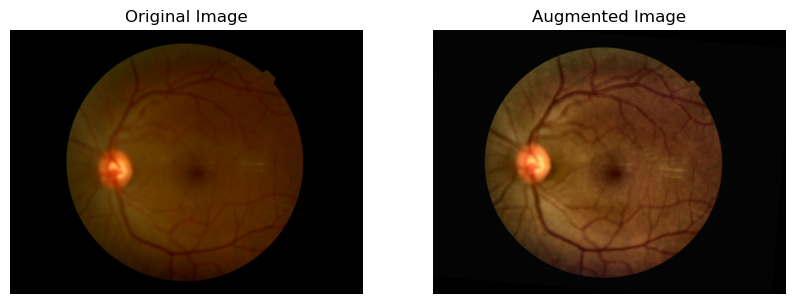

In [15]:
# Apply augmentation to a sample image
augmented_img = augmentation_pipeline(image=np.array(clahe_img))["image"]

# Show original vs augmented
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented_img)
plt.title("Augmented Image")
plt.axis("off")


plt.show()

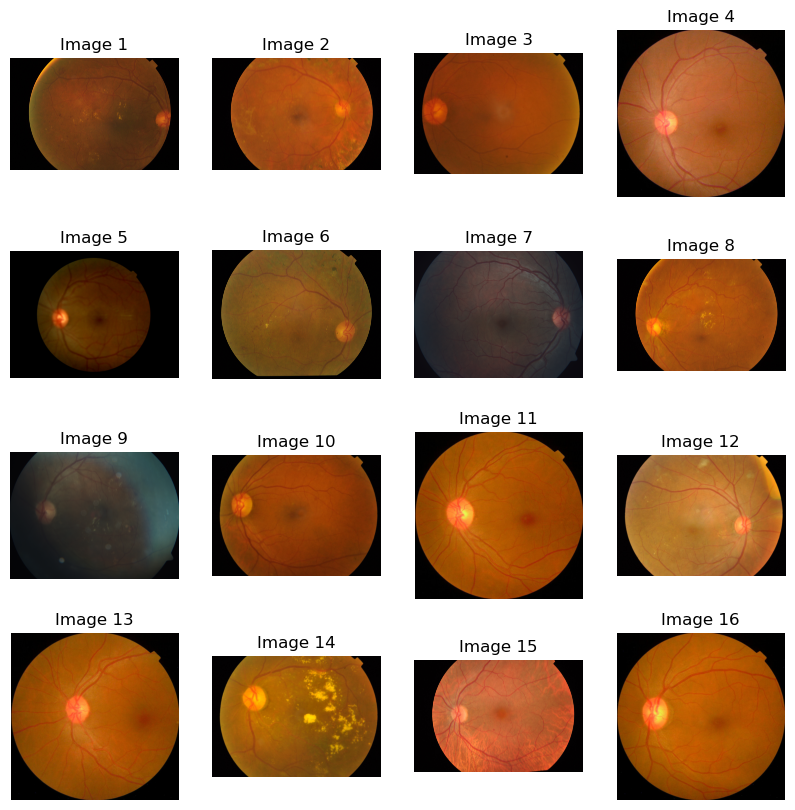

In [21]:
image_files = [f for f in os.listdir(dataset_path) if f.endswith('.png')][:16]

# Plot sample images
plt.figure(figsize=(10, 10))
for i, file in enumerate(image_files):
    img = cv2.imread(os.path.join(dataset_path, file))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert from BGR to RGB
    plt.subplot(4, 4, i + 1)
    plt.imshow(img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.show()

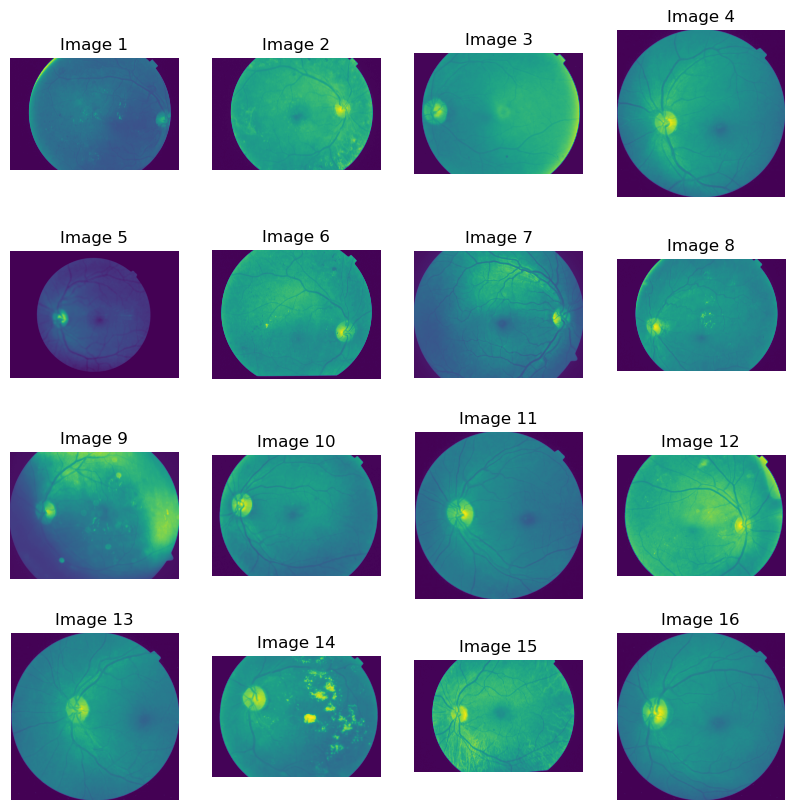

In [24]:
# convert to grayscale

# Plot sample images
plt.figure(figsize=(10, 10))
for i, file in enumerate(image_files):
    img = cv2.imread(os.path.join(dataset_path, file))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert from BGR to RGB
    img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    plt.subplot(4, 4, i + 1)
    plt.imshow(img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.show()

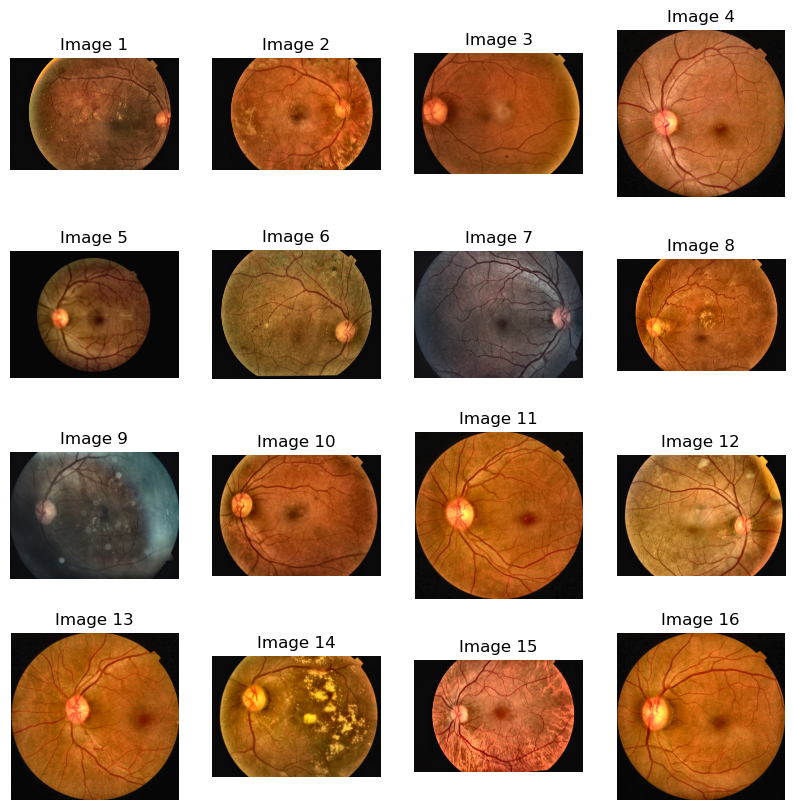

In [38]:
# Apply CLAHE

# Plot sample images
plt.figure(figsize=(10, 10))
for i, file in enumerate(image_files):
    img = cv2.imread(os.path.join(dataset_path, file))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert from BGR to RGB
    clahe_img = apply_clahe(img)
    plt.subplot(4, 4, i + 1)
    plt.imshow(clahe_img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.show()

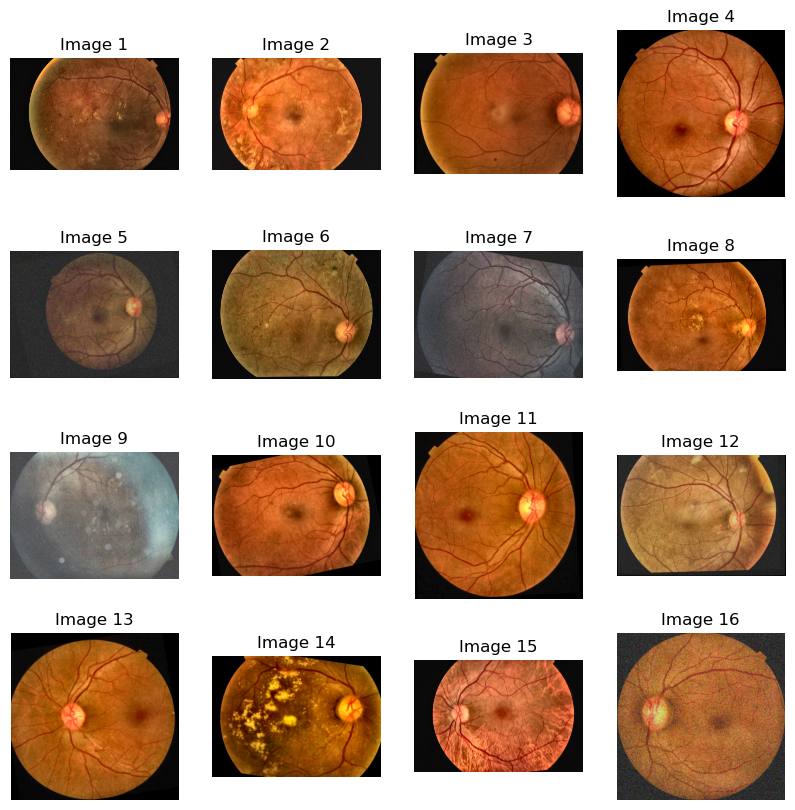

In [39]:
# Augmentation

# Plot sample images
plt.figure(figsize=(10, 10))
for i, file in enumerate(image_files):
    img = cv2.imread(os.path.join(dataset_path, file))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert from BGR to RGB
    clahe_img = apply_clahe(img)
    augmented_img = augmentation_pipeline(image=np.array(clahe_img))["image"]
    plt.subplot(4, 4, i + 1)
    plt.imshow(augmented_img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.show()

## Advance Augmentation

### MixUp

In [41]:
import numpy as np
import torch

def mixup(image1, image2, label1, label2, alpha=0.4):
    """ Mixes two images and their labels using a random lambda from Beta distribution. """
    lam = np.random.beta(alpha, alpha)  # Mix ratio
    mixed_image = lam * image1 + (1 - lam) * image2
    mixed_label = lam * label1 + (1 - lam) * label2
    return mixed_image, mixed_label


In [68]:
import cv2
import numpy as np
import torch

def get_resized_image_label(dataset_path, df, target_size=(512, 512)):
    """ Loads, resizes, and normalizes an image from the dataset """
    random_row = df.sample(1).iloc[0]
    img_path = os.path.join(dataset_path, f"{random_row['id_code']}.png")
    
    # Read the image
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert to RGB
    
    # Resize to a fixed shape
    img = cv2.resize(img, target_size)
    
    # Normalize image
    img = img / 255.0
    
    label = torch.tensor(random_row["diagnosis"], dtype=torch.float32)
    return img, label

# Example usage
img1, label1 = get_resized_image_label("../../DR Dataset/train_images/", df, target_size=(512, 512))
img2, label2 = get_resized_image_label("../../DR Dataset/train_images/", df, target_size=(512, 512))



In [69]:
print(img1.shape)
print(img2.shape)

(512, 512, 3)
(512, 512, 3)


(-0.5, 511.5, 511.5, -0.5)

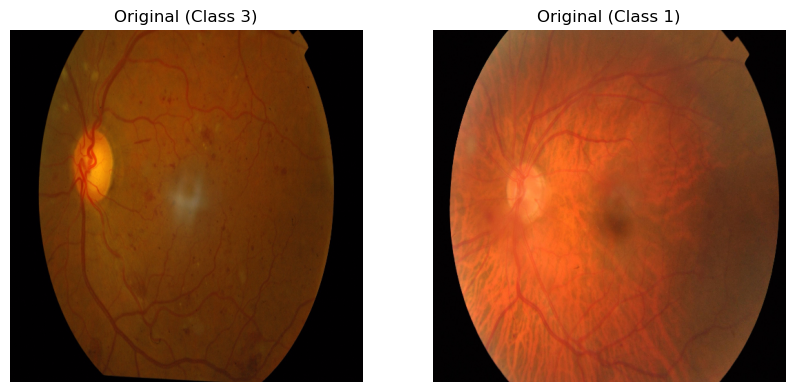

In [70]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img1)
plt.title(f"Original (Class {int(label1.item())})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img2)
plt.title(f"Original (Class {int(label2.item())})")
plt.axis("off")

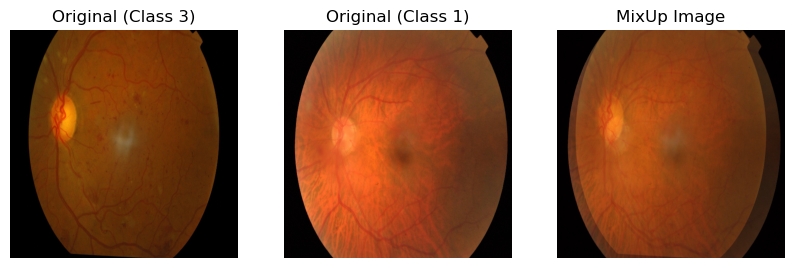

In [71]:
# Apply MixUp
mixed_img, mixed_label = mixup(img1, img2, label1, label2)

# Visualize MixUp
plt.figure(figsize=(10, 5))
plt.subplot(1, 3, 1)
plt.imshow(img1)
plt.title(f"Original (Class {int(label1.item())})")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(img2)
plt.title(f"Original (Class {int(label2.item())})")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mixed_img)
plt.title(f"MixUp Image")
plt.axis("off")
plt.show()